# BreastMNIST: breast ultrasound images as ResNet-50 embeddings

780 breast ultrasound images, labelled malignant or benign/normal. From
MedMNIST v2 (Yang et al., 2023, *Scientific Data*), based on the images of
Al-Dhabyani et al. (2020, *Data in Brief*). This project uses the 224 x 224
version (MedMNIST+, Zenodo record 10519652, CC BY 4.0).

Each image becomes 2,048 numbers: the output of an ImageNet ResNet-50 without
its last layer. These embedding dimensions are the features. With 2,048
features and 780 images, there are more features than images, as in SCAN-B.

- `BreastMNIST` (`breastmnist.py`) downloads the images, checks them against
  the published MD5, and computes and caches the embeddings.
- `load_xy` (`featsel_view.py`) returns X and y for scikit-learn.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parents[2]))  # repo root, so featsel_datasets imports

from featsel_datasets.medmnist_breastmnist.breastmnist import BreastMNIST

data = BreastMNIST()

## Files

The first use downloads the images (31 MB) and computes the embeddings once.
Later uses read the cached copies.

In [2]:
for path in sorted(data.cache_dir.glob('*.npz')):
    print(f'{path.stat().st_size / 1e6:6.1f} MB  {path.name}')

  30.9 MB  breastmnist_224.npz
   3.9 MB  embeddings_resnet50.npz


## Images and labels

MedMNIST v2 merged *normal* and *benign* into one class, against *malignant*.
It also fixed a train/val/test split. This project ignores that split: the
runner draws its own splits from all 780 images.

In [3]:
samples = data.samples
pd.crosstab(samples['label'], samples['split'], margins=True)

split,test,train,val,All
label,,,,
benign_or_normal,114,399,57,570
malignant,42,147,21,210
All,156,546,78,780


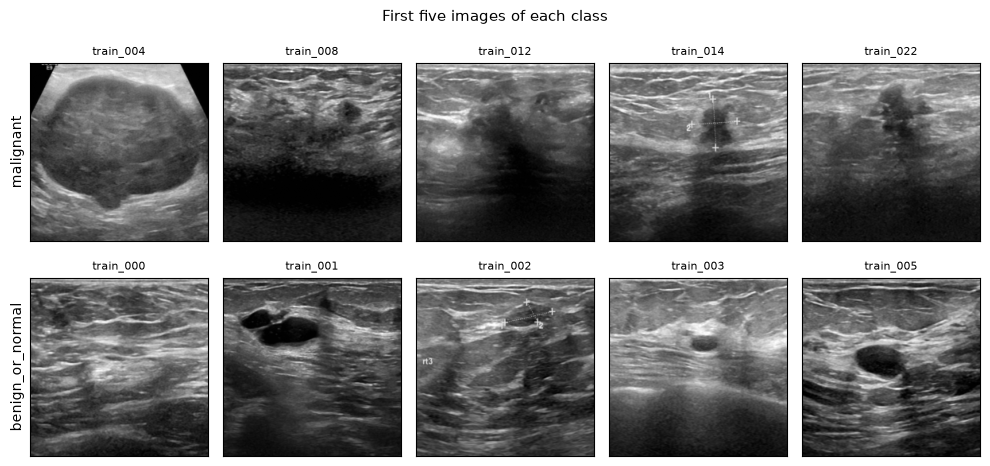

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.9))
for row, label in enumerate(['malignant', 'benign_or_normal']):
    picks = np.flatnonzero(samples['label'].to_numpy() == label)[:5]
    for ax, i in zip(axes[row], picks):
        ax.imshow(data.images[i], cmap='gray')
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_title(samples.index[i], fontsize=8)
    axes[row, 0].set_ylabel(label, fontsize=10)
fig.suptitle('First five images of each class', fontsize=11)
fig.tight_layout(h_pad=1.5)

Some images carry measurement marks ("+" calipers) drawn during the scan,
for example `train_014` and `train_002`. A model can learn such marks instead
of the tissue. The embeddings include them.

## Embeddings

ResNet-50 ends in a ReLU and an average pool, so values are never negative
and many are exactly zero.

In [5]:
X = data.embeddings
print(X.shape)
print('values from', X.values.min(), 'to', round(float(X.values.max()), 2))
print('share of exact zeros:', round(float((X.values == 0).mean()), 3))
X.iloc[:3, :6]

(780, 2048)
values from 0.0 to 9.99
share of exact zeros: 0.428


,resnet50_0000,resnet50_0001,resnet50_0002,resnet50_0003,resnet50_0004,resnet50_0005
train_000,0.000000,0.016968,0.0,0.000000,0.000000,0.000000
train_001,0.000000,0.018837,0.0,0.026078,0.014295,0.005518
train_002,0.548235,0.028507,0.0,0.000000,0.608458,0.000000


## Dependence between features

Feature selection methods differ most when features depend on each other.
Embedding dimensions are not independent: the absolute correlation between
pairs of dimensions, and the number of principal components needed to
explain most of the variance, show how much.

In [6]:
corr = np.corrcoef(X.values, rowvar=False)
pairs = np.abs(corr[np.triu_indices_from(corr, k=1)])
print(f'{len(pairs):,} pairs of dimensions')
print('median |r|      :', round(float(np.median(pairs)), 3))
print('share |r| > 0.5 :', round(float((pairs > 0.5).mean()), 4))
print('share |r| > 0.8 :', round(float((pairs > 0.8).mean()), 4))

centered = X.values - X.values.mean(axis=0)
variance = np.linalg.svd(centered, compute_uv=False) ** 2
explained = np.cumsum(variance) / variance.sum()
for share in (0.5, 0.9, 0.99):
    print(f'components for {share:.0%} of the variance:', int(np.searchsorted(explained, share)) + 1)

2,096,128 pairs of dimensions
median |r|      : 0.056
share |r| > 0.5 : 0.0017
share |r| > 0.8 : 0.0


components for 50% of the variance: 12
components for 90% of the variance: 150
components for 99% of the variance: 462


Pairs of dimensions are only weakly correlated, yet a few hundred
directions carry almost all the variance. The dependence is spread across
many dimensions at once, not concentrated in strongly correlated pairs. A
filter that only removes highly correlated pairs has little to remove here.

## Signal per dimension

A univariate F test per dimension, malignant against the rest. Bonferroni
over 2,048 tests sets the threshold.

In [7]:
from sklearn.feature_selection import f_classif

F, p = f_classif(X.values, samples['label'])
print('dimensions with p < 0.05 / 2048:', int((p < 0.05 / X.shape[1]).sum()), 'of', X.shape[1])
print('strongest five:', ', '.join(X.columns[np.argsort(p)[:5]]))

dimensions with p < 0.05 / 2048: 223 of 2048
strongest five: resnet50_1979, resnet50_0970, resnet50_0989, resnet50_1523, resnet50_1292


## This project's view

`load_xy` returns all 780 images and drops embedding dimensions with a single
value.

In [8]:
from featsel_datasets.medmnist_breastmnist.featsel_view import load_xy

X, y = load_xy(data)
print(X.shape)
y.value_counts()

(780, 2048)


label
benign_or_normal    570
malignant           210
Name: count, dtype: int64